# SQDMetal two transmons with a λ/2 bus resonator (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/2_transmons_wRes_comp.ipynb` with the SQDMetal
components `TransmonTaperedInsets`, `Smooth_Capacitor_Semicircle` and `ResonatorMeanderPinPin`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/2_transmons_wres_comp.md`).
Stored outputs: a layout plot, a Palace capacitance matrix and derived circuit parameters (5 × 2 mm chip, silicon
280 µm). Two floating tapered-pad transmons, each capacitively coupled through a semicircular "smooth" capacitor
on its inner top pad corner to one 8.96 mm λ/2 meander bus between them (6.8 GHz on Si). No feedline: a
bus-coupling study. Stated: f_q 4.5 GHz (L_J 13.203 / 13.196 nH), E_C ≈ 225 MHz, g ≈ 83 MHz, f_res 6.8 GHz.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 5 × 2 mm chip centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-2TR" |
| pads | none (Palace ports on the junctions; a bus-coupling study) | none: nothing for the pad rule (`frame.pad_edge`, 100 µm) |
| substrate | silicon, 280 µm | sapphire 650 µm, εr 10.25 |
| junctions | L_J 13.203 / 13.196 nH for 4.5 GHz (a junction line) | Quantcore trilayer junctions **sized for the stated 4.5 GHz**: 0.34 × 0.6 µm, L_J ≈ 9.9 nH — R_n ≈ 66 kΩ, ⚠ above the 40–50 kΩ window (a 45 kΩ junction would give ≈ 5.4 GHz) |
| cheese | none (`cap_sim.add_ground_plane()` without holes, a Gmsh mesh for Palace) | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonTaperedInsets` × 2, `Smooth_Capacitor_Semicircle` × 2, `ResonatorMeanderPinPin` | Quantcore re-implementations of the two SQDMetal cells (Apache-2.0) with the source options; the bus as a qcc meander route |
| placement | Q1 at −1.25 mm, Q2 at +1.65 mm (the layout is 200 µm east of its chip centre) | centred in the die: everything 200 µm west (Designer = source + (2300, 1000) µm) |

**Changed / estimated (kept from the earlier rebuild):**
- **`chrgln_pin_y_offset` +10 µm instead of the source's −10 µm.** With −10 the SQDMetal formulas put the
  capacitor's bite 10 µm off the pad end, so the capacitor overlaps the qubit pad (a short; components' finding,
  `test_semicircle_capacitor_on_the_qubit_pin[-10]`), while the stored plot and the Palace C-matrix show two
  separate conductors. 0 puts the pin exactly on the pocket edge (DRC open/short errors there); +10 is the other
  value consistent with the stored outputs: 4–15 µm gap, no overlap, a 20 µm lead to the pocket edge.
- **Bus length:** `ResonatorMeanderPinPin` runs 8960 µm from pin `a`, 25 µm (`gap_front`) inside each pad's back
  edge; our route runs between the ports `a` at the pocket edges, so it is 8960 − 2 × (25 + 20) = 8870 µm (the same
  physical line). The meander is KQC's (12 turns).
- **LOM capacitances** are lom's analytic estimates (pads 126 fF to ground, 37 fF pad–pad, capacitor 25 fF to the
  pad); the source's Palace values are 73.5 / 79.7 fF, 35.7 fF and 17.6 fF, so f_q and E_C differ from the source.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two tapered-inset transmons (the chip has no pads and no readout), the two semicircle capacitors snapped to them with the λ/2 bus between them, and then the whole chip (the targets, the sim group, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `2_transmons_wres_comp.v1.ipynb`; both save the same `2_transmons_wres_comp.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/2_transmons_wres_comp/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "2_transmons_wres_comp"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2500, 1000                              # Metal's 5 × 2 mm chip is centred on (0, 0)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** The stated target is f_q 4.5 GHz for both qubits. `size_junction(4.5, C_Σ)`
solves the trilayer junction on the PDK rule for each qubit's C_Σ (≈ 107 fF without the junction, from this
design's LOM before the rebuild: f_q 4.06 GHz with the source's 13.2 nH, C_J 0): straight fingers 0.34 µm ×
0.6 µm, L_J ≈ 9.9 nH, C_J ≈ 10.2 fF — **R_n ≈ 66 kΩ, above the 40–50 kΩ window**; the sizing lines print the
note. Kept: the target is the source's. `trilayer_junction` turns L_J into the cell's `junction_type` +
`junction_params` and the LOM junction.

In [5]:
from quantcore_circuits.circuit.bridges import size_junction
JJ_PARAMS, JUNCTION = {}, {}
for q, c in (("Q1", 106.7), ("Q2", 106.5)):
    s = size_junction(4.5, c, c_includes_junction=False)
    JJ_PARAMS[q], JUNCTION[q] = trilayer_junction("TransmonTaperedInsets", lj_nH=s.lj_nH)
    print(q, JUNCTION[q], f"R_n {s.rn_kohm:.0f} kΩ, fingers {s.finger_width} × {s.second_finger_width} µm;", *s.notes)

Q1 {'Lj_nH': 9.9036, 'Cj_fF': 10.2} R_n 67 kΩ, fingers 0.34 × 0.6 µm; R_n 66.5 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 116.8 fF needs E_J/h 16.4 GHz)
Q2 {'Lj_nH': 9.9036, 'Cj_fF': 10.2} R_n 67 kΩ, fingers 0.34 × 0.6 µm; R_n 66.7 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 116.6 fF needs E_J/h 16.4 GHz)


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand, segment by segment; a bus-coupling study has no pads,
no readout and no control lines, so those segments are one sentence each. Each segment with something in it is one
cell with one picture of the chip so far (live, KLayout redraws after every cell). The capacitors are **snapped** to
the qubits' pins and the bus runs between the capacitors, so the coupling comes after the qubits. Coordinates are the
source's + (`X0`, `Y0`) until the centring in Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID SQD-2TR) |
| 2 | bond pads: none (a capacitance / bus-coupling study: its only ports are the junctions) |
| 3 | readout line: none |
| 4 | the two `TransmonTaperedInsets` with their trilayer junctions |
| 5 | readout resonators: none (the only resonator is the bus, Design 6) |
| 6 | the coupling: the two semicircle capacitors on the qubits' inner pad corners and the 8.96 mm λ/2 bus |
| 7 | the control routing: none |
| 8 | the whole chip: the targets, the sim group, the centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 5 × 2 mm area sits
in its middle (source + (2500, 1000) µm; the centring step below moves the content a further 200 µm west). The
PDK frame: L dicing markers (1000/0), 3 × 3 alignment grids (1001/0), the chip boundary (100/0), the device ID on
a free edge. The chip `cheese` stays `"auto"`: the source has no cheese, so the PDK band is drawn.

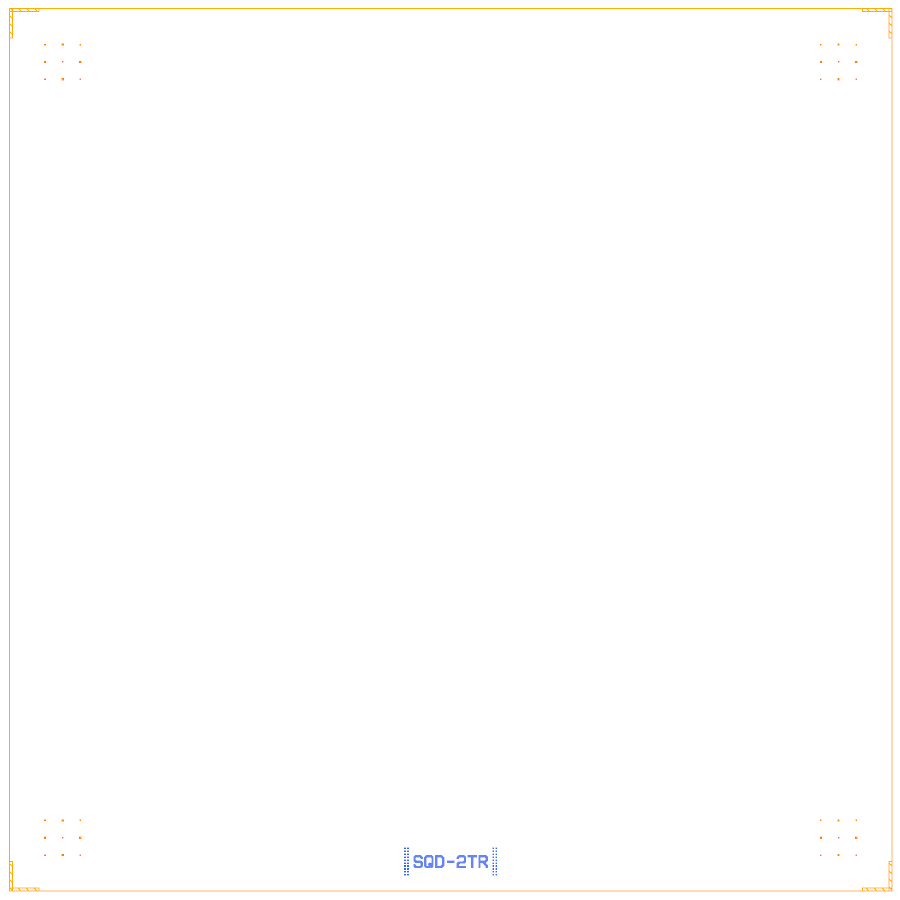

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/2_transmons_wres_comp/s1_die.png')

In [6]:
d = Designer("2_transmons_wres_comp", box=(-1250, -2750, 6250, 4750), chip={"name_chip": "SQD-2TR"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(900, 900), width=360)

## Design 2 · Bond pads: none on this chip

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"`). The source is a capacitance / bus-coupling study with no pads or launchers (its only ports are
the junctions), so there is nothing to place here.

## Design 3 · Readout line: none

No feedline and no readout: the source extracts a capacitance matrix and the circuit parameters from it.

## Design 4 · Qubit placement: two tapered-inset transmons

**Qubits:** `TransmonTaperedInsets` (Quantcore re-implementation of SQDMetal's, Apache-2.0) with the source
options: orientation 0, pocket 1000 × 420 µm, `pocket_lower_tighten` 0, `chrgln_pin_x_offset` 0 and
`chrgln_pin_y_offset` +10 (see above); SQDMetal defaults otherwise: 800 × 110 µm pads 100 µm apart, 40 µm tapers
to a 20 µm gap where the trilayer junction is drawn (`junction_params`). Ports: the placement pins
(`top_left_pin`, `top_right_pin`, `bottom_*_pin`, `*_pocket_pin`) and the junction points `squid_a` / `squid_b`.

The first picture is the whole die, the second the source's 5 × 2 mm area with both qubits.

<TransmonTaperedInsets Q1 ports=['bottom_left_pin', 'bottom_pocket_pin', 'bottom_right_pin', 'squid_a', 'squid_b', 'top_left_pin', 'top_pocket_pin', 'top_right_pin']>

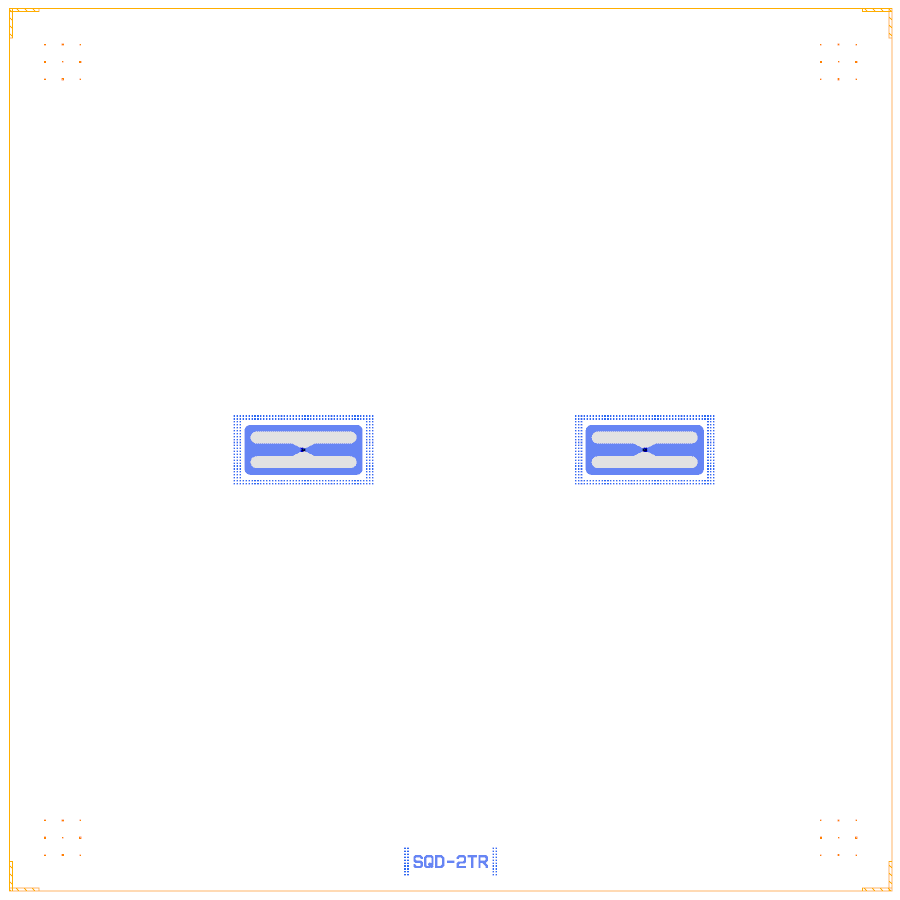

**On the chip so far:** 0 pads · 2 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

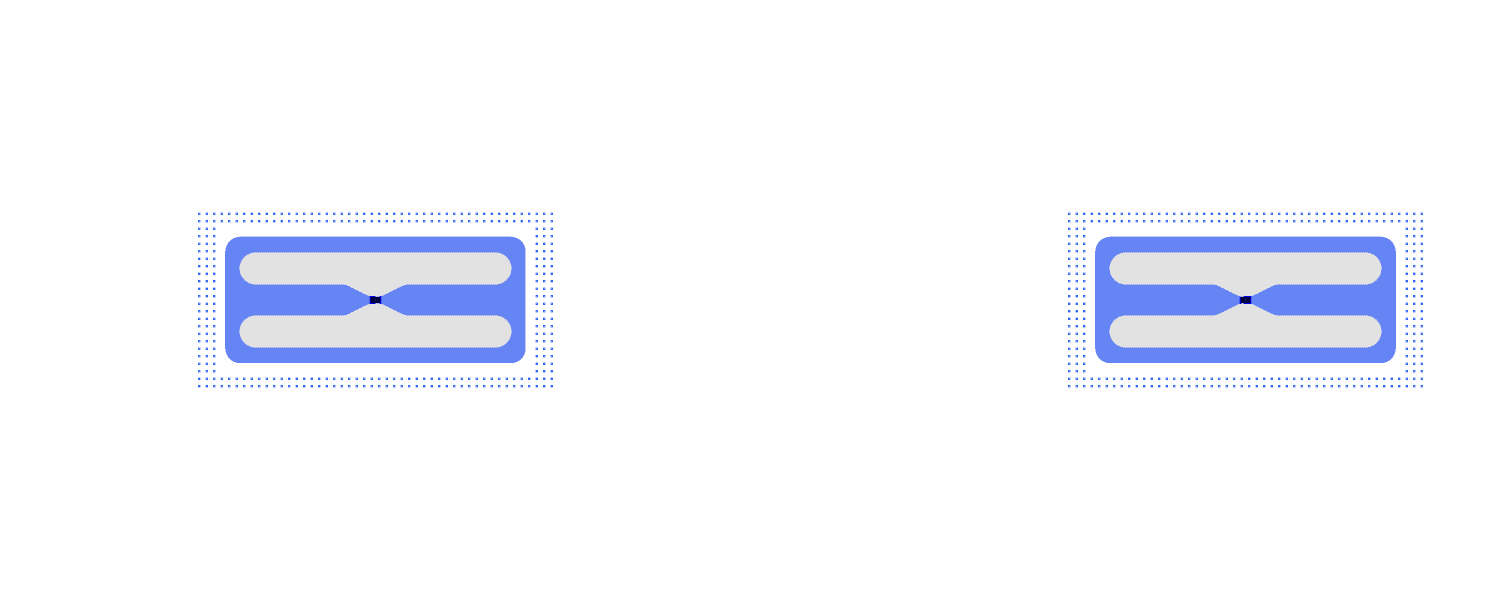

In [7]:
PIN_OFF = 10                                     # chrgln_pin_y_offset: source −10 overlaps the qubit pad (see above)
TTI = dict(pocket_height=420, pocket_lower_tighten=0, chrgln_pin_x_offset=0, chrgln_pin_y_offset=PIN_OFF)
with d.batch():
    q1 = d.add("Q1", "TransmonTaperedInsets", at=(X0 - 1250, Y0), junction=JUNCTION["Q1"], **JJ_PARAMS["Q1"], **TTI)
    q2 = d.add("Q2", "TransmonTaperedInsets", at=(X0 + 1650, Y0), junction=JUNCTION["Q2"], **JJ_PARAMS["Q2"], **TTI)
print(q1)
layout_step(d, STEPS / "s4_qubits.png", size=(900, 900), width=360)
snap(d, STEPS / "s4_area.png", box=(X0 - 2500, Y0 - 1000, X0 + 2500, Y0 + 1000), size=(1500, 600), width=600);

## Design 5 · Readout resonators: none

## Design 6 · Coupling: the two capacitors and the λ/2 bus

**Capacitors:** `SmoothCapacitorSemicircle` (re-implementation of `Smooth_Capacitor_Semicircle`) with the source
options — 160 × 80 µm pad, 60 µm semicircle, fillet 5 µm, resolution 20, orientation 180 / 0 — **snapped** to
`Q1.top_right_pin` / `Q2.top_left_pin` (`snap="target"`, `to=...`): the capacitor follows the qubit. Its port `a`
starts the bus.

**The bus** between the two capacitors' ports `a`: a meander of 8870 µm (the source's 8960 µm counted from SQDMetal's
pin `a` inside each pad, minus 2 × (25 + 20) µm), KQC's meander with 12 turns, r = 40 µm, CPW 10/6 µm. The qubits
couple to each other only through it (a λ/2 at ≈ 6.6 GHz, ≈ 2 GHz above them). The picture shows the source's area.

<TransmonTaperedInsets Q1 ports=['bottom_left_pin', 'bottom_pocket_pin', 'bottom_right_pin', 'squid_a', 'squid_b', 'top_left_pin', 'top_pocket_pin', 'top_right_pin']>
<SmoothCapacitorSemicircle C1 ports=['a', 'target']>


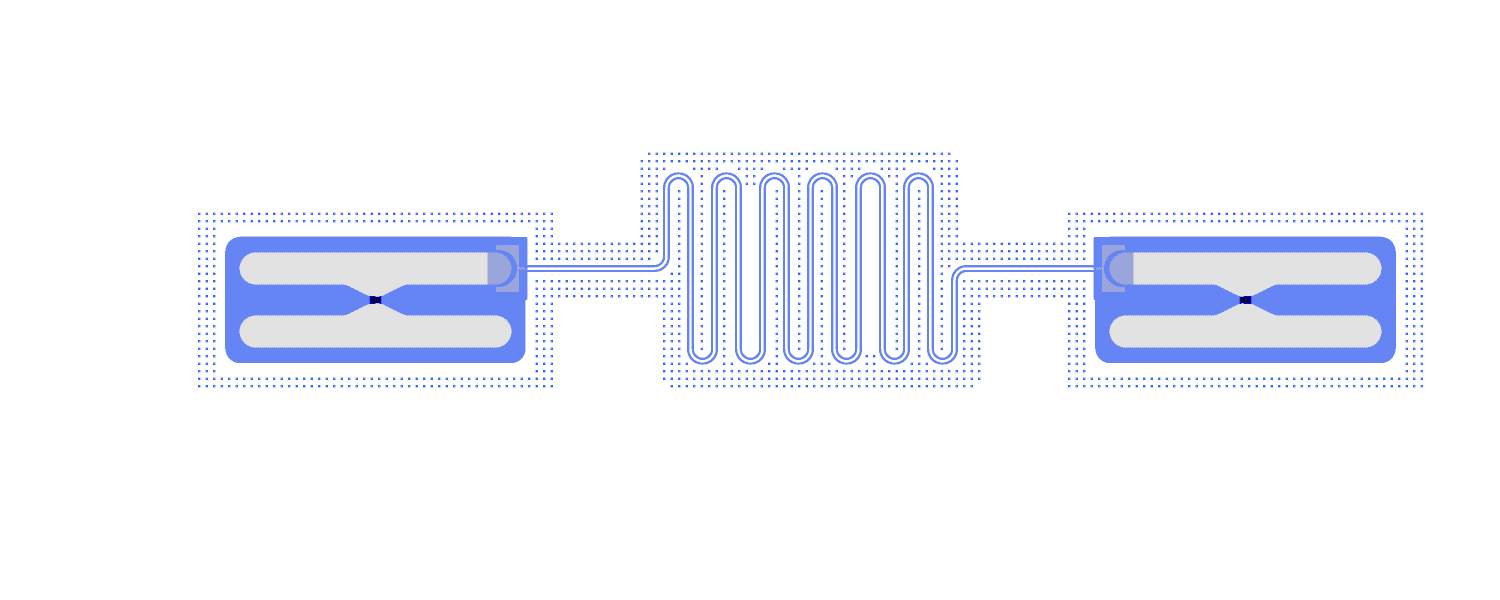

**On the chip so far:** 0 pads · 2 qubits · 2 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `C1`, `C2` and 1 route(s) `BUS`.

BUS 8870.0 µm


In [8]:
CAP = dict(rect_width=160, rect_length=80, semi_radius=60, fillet_radius=5, fillet_resolution=20,
           lead_length=30 - PIN_OFF)             # lead from the pad's back edge to the pocket edge
with d.batch():
    c1 = d.add("C1", "SmoothCapacitorSemicircle", snap="target", to=q1.top_right_pin, orientation=180, **CAP)
    c2 = d.add("C2", "SmoothCapacitorSemicircle", snap="target", to=q2.top_left_pin, orientation=0, **CAP)
print(q1, c1, sep="\n")
PIN_A_INSET = 25.0                               # SQDMetal pin a: gap_front (25 µm) inside the pad's back edge
L_BUS = 8960 - 2 * (PIN_A_INSET + CAP["lead_length"])   # route between the two ports a (source total from pin a)
d.route("BUS", c1.a, c2.a, meander=L_BUS, r=40).set(meanders=12)
layout_step(d, STEPS / "s6_bus.png", box=(X0 - 2500, Y0 - 1000, X0 + 2500, Y0 + 1000), size=(1500, 600), width=600)
print("BUS", round(d.result.route_lengths()["BUS"], 1), "µm")

## Design 7 · Routing: no control lines

The cells' placement pins mark where charge lines could attach; the source uses none.

## Design 8 · The whole chip: targets, sim group, centring, save

**Targets, sim group, centring, save.** The stated targets (f_q 4.5 GHz, bus 6.8 GHz on silicon) go into the
design; one sim group holds the whole circuit (a Q3D C-matrix — the source's own analysis — and an eigenmode / EPR
job). `center_in_die` applies the PDK placement rule: the source's layout sits 200 µm east of its own chip
centre (Q1 at −1.25 mm, Q2 at +1.65 mm), so the content moves 200 µm west (the capacitors follow their snaps, the
bus its ports). Then the design is saved with `save_design`, which compares it with
the file it replaces (the previous run's): it should say *same design*, and the file keeps the previous key order.

centring shift (µm): (-200.0, 0.0)


**Same design as before:** `examples/designs/sqdmetal/2_transmons_wres_comp.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer 2_transmons_wres_comp: 4 instances, 1 routes, live=False> → examples\designs\sqdmetal\2_transmons_wres_comp.json | BUS 8870.0 µm


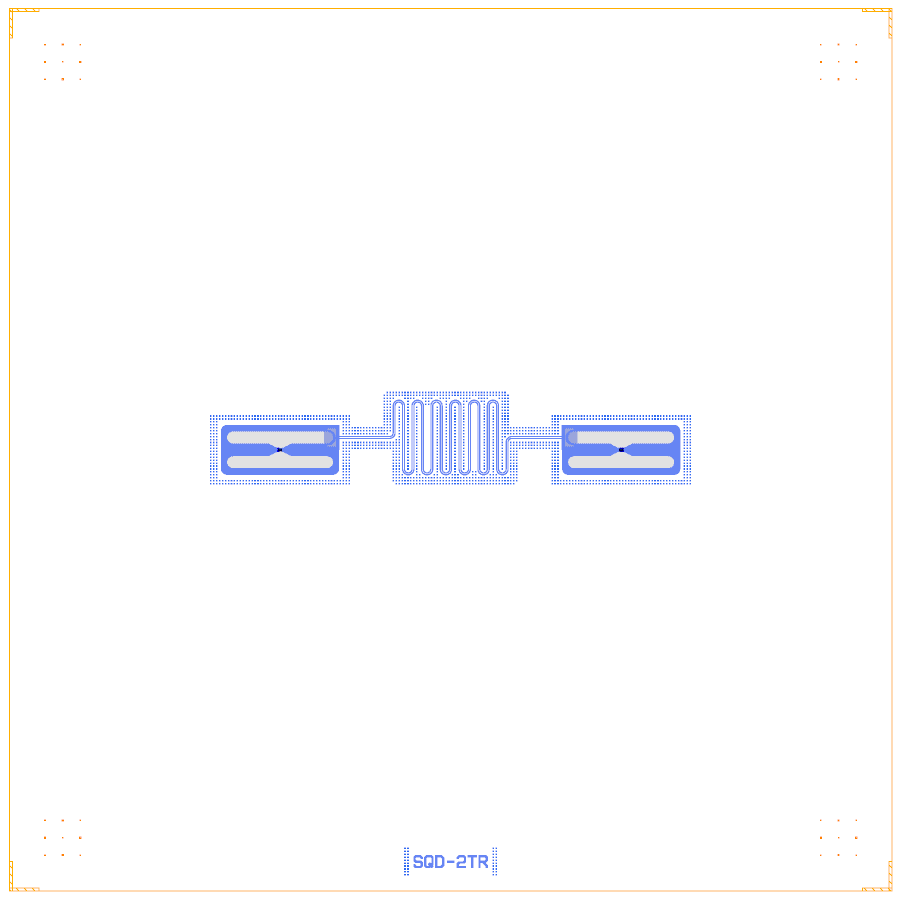

**On the chip so far:** 0 pads · 2 qubits · 2 other components · 1 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/2_transmons_wres_comp/s8_chip.png')

In [9]:
d.targets(Q1={"f_q_GHz": 4.5}, Q2={"f_q_GHz": 4.5}, BUS={"f_GHz": 6.8})
d.sim_group("ALL", ["Q1", "Q2", "C1", "C2", "BUS"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN, same = save_design(d, OUT / "2_transmons_wres_comp.json")
display(Markdown(same))
print(d, "→", DESIGN, "| BUS", round(d.result.route_lengths()["BUS"], 1), "µm")
layout_step(d, STEPS / "s8_chip.png", size=(900, 900), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here (from the v1 run): **no errors**; `dangling_port` warnings for the unused `TransmonTaperedInsets` placement pins
(`top_left_pin` of Q1, `top_right_pin` of Q2, the `bottom_*_pin` and `*_pocket_pin`: SQDMetal's marks for charge
lines or capacitors, not CPW ends) and the junction points `squid_a` / `squid_b`. PDK design warnings: `pdk_rn` on
both qubits (R_n ≈ 66 kΩ, sized for the stated 4.5 GHz; flagged, not retuned).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` maps the ports onto circuit nodes. Each `TransmonTaperedInsets` is a floating transmon: two pad nodes
(`island1`, `island2`) with C to ground and between them, the junction across them. Each semicircle capacitor is a
C from the qubit's top pad to its port node; the bus between the two capacitor ports is a λ/2 `TLres` (capacitive at
both ends). The netlist lists the unused placement pins as unconnected (nothing attaches there).

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**C1 / C2 / BUS ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("C1.", "C2.", "BUS", "Q1.top_right", "Q2.top_left")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat normal modes of the whole circuit and the QuTiP-dressed values next to the stated targets (f_q 4.5 GHz,
bus 6.8 GHz — on silicon; on sapphire the bus lands a little lower). The two qubits are sized identically, so they
hybridise through the bus (participations ≈ 0.5 / 0.5): the per-qubit α and the ZZ are then not meaningful (the
ZZ table says "hybridised"), and the mode table's A column is the per-mode anharmonicity of the pair. Expected:
f_q ≈ 4.7 GHz, bus ≈ 6.6 GHz (the v1 run: QuTiP f_q 4.513 / 4.519 GHz, bus 6.565 GHz, qubit splitting 7.3 MHz); f_q sits a little above the target because the sizing used the pre-rebuild C_Σ and
the drawn junction adds its own C_J. The coupling g follows from the splitting of the two qubit modes (≈ Δf / 2,
the qubits being degenerate).

In [ ]:
res = simulate_lom(lb, d.design, max_modes=3)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q1": {"f_q_GHz": 4.5}, "Q2": {"f_q_GHz": 4.5}, "BUS": {"f_GHz": 6.8}})))
display(Markdown(zz_md(res)))
qm = [m for m in res.modes if m.kind == "qubit"]
print(f"qubit-qubit splitting {abs(qm[1].f_GHz - qm[0].f_GHz) * 1e3:.1f} MHz (bus-mediated, degenerate qubits)")

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes (QuCat; circles are the two hybridised qubit modes, the square the
bus; filled markers are the QuTiP dressed values; red bars are the design's targets), (b) the bus's dispersive shift
|χ|.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", targets={"Q1": {"f_q_GHz": 4.5}, "Q2": {"f_q_GHz": 4.5},
                                                    "BUS": {"f_GHz": 6.8}}, title="2_transmons_wres_comp: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. Shorten the bus from 8870 to 8400 µm: its λ/2 mode rises by ≈ 5 % (≈ +0.35 GHz), moving away from the qubits, so
the bus-mediated qubit–qubit splitting shrinks. Done on a copy (`design_copy`), so `2_transmons_wres_comp.json`
keeps the source's length.

In [ ]:
d2 = design_copy(DESIGN)
d2["BUS"].set(meander=8400)
after = simulate_lom(d2.lom(), d2.design, max_modes=3)
display(Markdown("**BUS: 8870 → 8400 µm**\n\n" + params_delta_md(res, after)))
for name, r in (("before", res), ("after", after)):
    qm = [m for m in r.modes if m.kind == "qubit"]
    bus = next(m for m in r.modes if m.kind == "resonator")
    print(f"{name}: bus {bus.f_GHz:.4f} GHz, qubit splitting {abs(qm[1].f_GHz - qm[0].f_GHz) * 1e3:.1f} MHz")

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/sqdmetal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).


**Export limit, check it (reported to components earlier):** the junction ports' reference points land inside the
20 µm taper-tip gap, with no metal edge there; an earlier export logged "Unable to create polygon for port" and put
each qubit's two pads on one excitation (no `Q1.island2` net). The v1 run's job table lists `Q1.island1`,
`Q1.island2`, `Q2.island1` and `Q2.island2`, so read the table below (and the export log) before comparing with the
source's pad-to-pad 35.7 fF.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/sqdmetal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of the sim group (the source's own analysis)
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "ALL", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrix

The source's own analysis (a Palace capacitance matrix there, Q3D here): the four qubit pads, the two capacitors and
the bus as named nets. The source states its values (pads 73.5 / 79.7 fF to ground, 35.7 fF pad–pad, 17.6 fF
capacitor), the numbers to compare with. Each net is named after its LOM node, so the matrix goes straight into the
circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are
none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode: each junction is a lumped L_J ‖ C_J sheet; with no line leaving the box the modes'
Q is the box's own (no 50 Ω port). pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) gives
the dressed qubit frequencies, the bus mode and the dispersive shifts.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run: none here

A driven run computes S-parameters between ports, and this chip has none besides the junctions (no pads, no line),
as the source; so there is no driven job. The eigenmode run is the full-wave answer here.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by Q1's junction participation p_J, with the LOM's frequencies (both qubits, the bus) as dashed lines. The
table below lists the modes and the pyEPR values.

In [ ]:
f_bus = res.params.get("BUS.f_GHz")              # the LOM's bus frequency (LOM 1)
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "Q2": res.params.get("Q2.f_q_GHz"), "BUS": f_bus}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: each qubit's mode is the one its own junction participates in most, the bus's
the remaining mode nearest the LOM's bus frequency; pyEPR's dressed frequencies and Kerr terms. `epr_values` pairs a
qubit with a resonator, so it is called once per qubit with the bus as the resonator (the second call adds Q2's
values and its χ to the bus).

In [ ]:
fem_values = {}
if keep_eig["ALL"]:
    fem_values = epr_values(keep_eig["ALL"], {"Q1": "BUS"}, {"BUS": f_bus})
    v2 = epr_values(keep_eig["ALL"], {"Q2": "BUS"}, {"BUS": f_bus})
    fem_values.update({k: x for k, x in v2.items() if k.startswith("Q2.")})
    if "BUS.chi_MHz" in v2:
        fem_values["BUS.chi_Q2_MHz"] = v2["BUS.chi_MHz"]
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for k, x in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list both qubits' f_q and α, the bus's f and "
          "its χ to each qubit from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name)
and the same LOM runs again — with the Palace-like capacitances the source quotes, f_q and E_C move towards its
values. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1), next to the design's targets (f_q 4.5 GHz, bus 6.8 GHz).

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "Q2.f_q_GHz", "Q2.alpha_MHz", "BUS.f_GHz", "BUS.chi_MHz"]
rows, on_fem = [], {}
if keep_q3d["ALL"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["ALL"]), max_modes=3).params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the qubits' f_q and α and the bus's f and χ of the "
          "LOM next to the LOM on the Q3D C-matrix and the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the design's targets

The design has its own targets (the source's): **both qubits at 4.5 GHz** and **the bus at 6.8 GHz**. From the v1
run the LOM puts both qubits inside their tolerance (4.513 / 4.519 GHz, f_q ± 20 MHz) and the bus 235 MHz low
(6.565 GHz, ± 10 MHz): the bus needs to be shorter. `loop.feedback` tunes qubit–readout pairs; here the only
resonator is a bus shared by two degenerate, hybridised qubits, so the feedback is the first-order rule of the λ/2
instead: f ∝ 1/ℓ, so the new length is ℓ · f / f_target (≈ −300 µm here). The bus has no waypoints (its path is its
meander), so shortening it is safe. When a solve is kept, the LOM's bus is first scaled by FEM / LOM (`SCALE`: the
eigenmode's bus, else the LOM on the Q3D C-matrix), so the step aims at the FEM value. The revisions are copies of the
design (with its targets), saved as `build/2_transmons_wres_comp_rev<k>.json`.

In [ ]:
import json

TARGETS_D = json.loads(Path(DESIGN).read_text(encoding="utf-8"))["targets"]   # the design's own targets
F_T, F_TOL = TARGETS_D["BUS"]["f_GHz"], 0.010   # the bus target and tolerance (GHz)
f_fem = fem_values.get("BUS.f_GHz") or on_fem.get("BUS.f_GHz")
SCALE = f_fem / f_bus if f_fem else 1.0          # FEM / LOM at the drawn bus (1: the LOM alone)
L0 = float(d.data["routes"]["BUS"]["length"])
L1 = rule_step(L0, SCALE * f_bus, F_T, -1.0)
rows = [f"| `{q}.f_q_GHz` | {TARGETS_D[q]['f_q_GHz']:g} ± 0.02 | {res.params.get(f'{q}.f_q_GHz'):.4f} | – (on target: "
        f"{abs(res.params.get(f'{q}.f_q_GHz') - TARGETS_D[q]['f_q_GHz']) <= 0.02}) |" for q in ("Q1", "Q2")]
rows.append(f"| `BUS.f_GHz` | {F_T:g} ± {F_TOL:g} | {SCALE * f_bus:.4f} ({'FEM' if f_fem else 'LOM'}) | "
            f"`BUS.length` {L0:.1f} → **{L1:.1f} µm** (f ∝ 1/ℓ) |")
display(Markdown("| target | value | now | step |\n|---|---|---|---|\n" + "\n".join(rows)))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the bus length, its LOM runs (× `SCALE`), and the next step uses
the exponent of the last two points (a secant), until the bus is within 10 MHz or `MAX_ITER` steps are made. With
`RUN_FEM = True` each revision's eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and the
loop closes on the FEM's bus. Each row also keeps the qubits' frequencies, printed below the table: they move little
(the bus is ≈ 2 GHz away).

In [ ]:
QUBITS = {}


def f_bus_of(k, it):
    """Revision it: the bus k µm long; its frequency on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2 = design_copy(DESIGN, f"_rev{it}")
    d2["BUS"].set(meander=k)
    path = d2.save(Path("build") / f"2_transmons_wres_comp_rev{it}.json")
    r = simulate_lom(d2.lom(), d2.design, max_modes=3)
    QUBITS[it] = (r.params.get("Q1.f_q_GHz"), r.params.get("Q2.f_q_GHz"))
    if RUN_FEM:
        job = export_sims(path, ["ALL"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["ALL"]
        f = epr_values(keep, {"Q1": "BUS"}, {"BUS": r.params.get("BUS.f_GHz")}).get("BUS.f_GHz") if keep else None
        if f:
            return f, path
    return SCALE * r.params.get("BUS.f_GHz"), path


history = rule_iterate(f_bus_of, "BUS.f_GHz", "BUS.length", L0, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                       start=(SCALE * f_bus, DESIGN), fem=bool(RUN_FEM))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("LOM qubit frequencies per revision (GHz):", {k: tuple(round(f, 4) for f in qs if f is not None)
                                                    for k, qs in QUBITS.items()})

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `2_transmons_wres_comp.json` (saved in Design 8) is the whole design:
`qcc build examples/designs/sqdmetal/2_transmons_wres_comp.json` rebuilds `build/2_transmons_wres_comp.oas` + its
sidecar, and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (a Gmsh mesh with a plain ground plane), so the PDK band stands — drawn in the
build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only (`FULL_FAB`);
`qcc mask examples/designs/sqdmetal/2_transmons_wres_comp.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The source's 5 × 2 mm area (compare the source's layout plot); Q1 with its semicircle capacitor; its trilayer
junction in the taper-tip gap; the capacitor around the pad end; the die frame's south-west corner (dicing L on
1000/0, 3 × 3 alignment grid on 1001/0); and Q1 in the **fab view** (the mask from Fab 1: 1/0 with the PDK
cheese band, the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary 100/0 is drawn as an
outline and the cheese band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

In [ ]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]          # Q1 after centring
cx = qx + 1250                                              # centre of the source's chip area
show_snapshot(d, OUT / "2_transmons_wres_comp.png", box=(cx - 2500, qy - 1000, cx + 2500, qy + 1000), size=(1800, 720), width=720)
show_snapshot(d, OUT / "2_transmons_wres_comp_q1.png", box=(qx - 550, qy - 300, qx + 650, qy + 400), size=(1200, 700), width=480)
show_snapshot(d, OUT / "2_transmons_wres_comp_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "2_transmons_wres_comp_cap.png", box=(qx + 340, qy - 10, qx + 550, qy + 220), size=(840, 920), width=320)
show_snapshot(d, OUT / "2_transmons_wres_comp_frame.png", box=(-1250, -2750, -350, -1850), size=(900, 900), width=300)
snap_file(Path("build") / "2_transmons_wres_comp_fab.oas", OUT / "2_transmons_wres_comp_fab_q1.png",
          box=(qx - 600, qy - 400, qx + 600, qy + 400), size=(1200, 800), width=480);

## Summary

| | |
|---|---|
| **matches the source** | both `TransmonTaperedInsets` and semicircle capacitors with the source options and relative positions; the 8960 µm λ/2 bus (8870 µm between our ports); the stated targets; the C-matrix sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; content centred (200 µm west of the source's own placement); sapphire; Quantcore trilayer junctions sized for 4.5 GHz (R_n ≈ 66 kΩ); the PDK cheese band in the mask |
| **changed / estimated** | `chrgln_pin_y_offset` +10 µm (−10 overlaps the pad); analytic LOM capacitances (larger than the source's Palace values) |
| **pads** | none in the source: nothing for the pad rule (100 µm) |
| **PDK design warnings** | `pdk_rn` on Q1 and Q2 (≈ 66 kΩ, sized for the stated 4.5 GHz) |
| layout | built in segments (die, the two qubits, the capacitors and the bus, the whole chip; no pads, readout or control lines); the saved JSON is the v1 notebook's |
| feedback | the design's targets: the qubits are on target in the LOM (v1 run); the bus → 6.8 GHz by the λ/2 rule on its length, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; check the junction-port nets (Simulate 1) |